# 01 · Exploración y validación de los datos

**Qué hay en los datos, si se procesaron bien y qué trampas tienen** antes de
usarlos para nada. Todo es de una sola tienda: el programa de gestión factura
para más de un punto de venta, y el estudio se centra en uno.

| Fuente | Granularidad | Cobertura | Papel |
|---|---|---|---|
| **Cierre Z semanal** | Semana | 135 semanas, 2024-01-01 → 2026-08-02 | **La serie del modelo** |
| **Diario de ventas por artículo** | Mes | 31 meses, 2024-01 → 2026-07 | Detalle de surtido y evolución |

Las dos salen del mismo programa de gestión, que ofrece 65 informes distintos.
Se eligieron estos dos porque son los que cubren toda la ventana con la
resolución necesaria: la semana para prever la venta y el artículo para
estudiar el surtido.

**Conclusiones principales:**
- Los informes cuadran consigo mismos, pero eso **no garantiza que estén
  completos**: la plataforma perdió 506 documentos de venta en julio de 2026 y
  solo la numeración de los tickets lo delata (apartado 2.2).
- Tres columnas del informe por artículo no miden lo que su nombre sugiere
  (apartado 4).
- La venta está muy concentrada: el **5,2 %** de los artículos hace la mitad de
  la facturación (apartado 5).

*El análisis de surtido, precios y márgenes está en `02-descriptivo-surtido.ipynb`.*

**Este notebook no procesa nada: solo lee `datos_limpio/`.** Esa carpeta la
generan dos canalizaciones independientes, que se lanzan juntas con
`python actualizar_datos.py`. Los informes originales no se modifican nunca.

```
datos_bruto/                    ·  solo lectura, tal y como lo descarga el TPV
│
├── Diario de ventas por artículo …/      31 CSV, uno por mes
│        │
│        └─▶ procesar_lote.py  ·  parser_tpv.py
│                 │
│                 └─▶ datos_limpio/  <MM-AAAA>.csv          un limpio por bruto,
│                                    consolidado_mensual.parquet   con el mismo
│                                    informe_procesado.csv    nombre para poder
│                                                            cotejarlos a ojo
│
└── Informes Z semanal/                  135 PDF, uno por semana
         │
         └─▶ procesar_lote_cierre_z.py  ·  parser_cierre_z.py
                  │
                  └─▶ datos_limpio/  serie_semanal.parquet        ◀── LA SERIE
                                     serie_semanal_departamentos.parquet
                                     serie_semanal_impuestos.parquet
                                     informe_procesado_cierre_z.csv
```

**Son independientes a propósito:** si un mes de artículos falla, la serie
semanal se regenera igual, y al revés. Las dos se detienen si el lote mezcla
puntos de venta distintos, porque consolidarlos falsearía la serie.

**Lo que la canalización del cierre Z hace además de leer el PDF:**

1. **Comprueba el periodo.** El nombre del fichero (`AAAA-MM-DD_AAAA-MM-DD.pdf`)
   tiene que coincidir con la `FECHA` que declara el PDF; si no, falla, para
   que un fichero mal nombrado no desalinee la serie en silencio.
2. **Hace cuatro comprobaciones por semana**: venta contra documentos, venta
   contra departamentos, venta neta contra el bloque de impuestos y
   **continuidad de la numeración de documentos**. La última es la única que
   detecta ventas que nunca llegaron a la plataforma, porque **el informe
   cuadra consigo mismo aunque le falten**.
3. **Corrige la semana del 6-12 de julio de 2026** con los arqueos que imprime
   la caja, y la marca con `corregida = True`.
4. **Deflacta a impuestos constantes**: `venta_neta_real` usa el IPC de
   alimentos de Almería promediado sobre los días de cada semana y neutraliza
   los cambios de IVA, que fueron cinco dentro de la ventana. Este notebook
   trabaja en euros corrientes; lo deflactado se analiza en el 02 y el 03.

**Si algo no cuadra, se arregla en la canalización y se vuelve a ejecutar,
nunca a mano sobre los datos.**

In [1]:
import sys

sys.path.insert(0, "../src")

import re
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

GUARDAR_FIGURAS = True     # exporta a reports/figuras/ en PNG 150dpi + SVG
FIGURAS = Path("../reports/figuras")


def guardar(fig, nombre):
    """Exporta la figura con el prefijo del notebook, en PNG y SVG.

    Sin sufijo de periodo, a diferencia del notebook 02: este cubre todo el
    histórico disponible, así que al reejecutarlo la figura se sustituye en
    vez de acumular una por cada corte de datos.
    """
    if not GUARDAR_FIGURAS:
        return
    FIGURAS.mkdir(parents=True, exist_ok=True)
    base = FIGURAS / f"01-{nombre}"
    fig.savefig(base.with_suffix(".png"), dpi=150, bbox_inches="tight")
    fig.savefig(base.with_suffix(".svg"), bbox_inches="tight")
    print(f"  guardada {base.name}.png / .svg")


AZUL = "#2a78d6"
ROJO = "#c0392b"
AMARILLO = "#e0a72e"
TINTA = "#0b0b0b"
TINTA_SEC = "#52514e"
GRID = "#e1e0d9"

plt.rcParams.update({
    "axes.edgecolor": GRID,
    "axes.labelcolor": TINTA_SEC,
    "xtick.color": TINTA_SEC,
    "ytick.color": TINTA_SEC,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

def num(valor, dec=2, signo=False):
    """Formatea a la convención española: millares con punto, decimales con coma.

    5355.29 -> '5.355,29'. Es el inverso de cómo escribe los números el TPV
   (coma de millares, punto decimal): eso es cómo llega el
    dato, esto es cómo se presenta en un documento en castellano.
    """
    if valor is None or (isinstance(valor, float) and np.isnan(valor)):
        return "—"
    crudo = f"{valor:{'+' if signo else ''},.{dec}f}"
    # Intercambio en dos pasos, con un centinela, para no pisar el separador
    # que acabo de escribir.
    return crudo.replace(",", "\x00").replace(".", ",").replace("\x00", ".")


# Las tablas de pandas (.to_string(), .describe()) tambien pasan por aqui.
pd.options.display.float_format = num

MESES_ES = ["enero", "febrero", "marzo", "abril", "mayo", "junio",
            "julio", "agosto", "septiembre", "octubre", "noviembre", "diciembre"]


def dia_mes_es(fecha):
    """'2024-08-26' -> '26 ago'. Fecha corta en castellano, sin depender del
    locale del sistema, que en esta maquina responde en ingles."""
    return f"{fecha.day:02d} {MESES_ES[fecha.month - 1][:3]}"

def formatear_mes_es(fecha_num, _pos=None):
    """Formatea una fecha de eje como 'mes año' en español (ej. 'enero 2024')."""
    fecha = mdates.num2date(fecha_num)
    return f"{MESES_ES[fecha.month - 1]} {fecha.year}"


def eje_fechas_es(ax, intervalo_meses=2):
    """Aplica a `ax` el mismo formato de fechas en español, con la misma
    frecuencia de marcas, en todos los gráficos de la serie semanal."""
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=intervalo_meses))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(formatear_mes_es))
    ax.tick_params(axis="both", labelsize=9)
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right")


def formatear_miles_es(valor, _pos=None):
    """Millares con punto para las marcas de los ejes: 800000 → 800.000.

    Sin decimales, a diferencia de num(): en un eje estorban.
    """
    return num(valor, 0)


def eje_miles(ax, eje="y"):
    """Separador de millares en el eje indicado ('x', 'y' o 'ambos').

    Solo para ejes de dinero con miles. No usarlo en porcentajes ni en el
    ticket medio, donde los valores son de dos cifras y el separador sobra.
    """
    formato = mticker.FuncFormatter(formatear_miles_es)
    if eje in ("x", "ambos"):
        ax.xaxis.set_major_formatter(formato)
    if eje in ("y", "ambos"):
        ax.yaxis.set_major_formatter(formato)


def marcar_corregidas(ax, c, columna):
    """Señala las semanas cuyo valor no sale entero de la plataforma del TPV.

    La plataforma del TPV perdio 2 dias de ventas y la semana se corrige con
    los arqueos de caja. La semana del 6-12 jul 2026 llegó incompleta (la
    plataforma perdió 506 documentos de dos días que la tienda sí vendió) y
    está reconstruida con los arqueos que imprime la caja. Es un dato válido y
    comparable, así que se dibuja en la línea como cualquier otro: lo que se
    marca es su procedencia, no una anomalía.
    """
    if "corregida" not in c.columns:
        return
    corr = c[c["corregida"].fillna(False)]
    if corr.empty:
        return
    ax.scatter(corr["periodo_inicio"], corr[columna], facecolor="none",
               edgecolor=TINTA, linewidth=1.4, s=90, zorder=6,
               label="reconstruida con arqueos de caja")


def cargar_festivos_semana(c):
    """Festivos de festivos_tienda.csv, unidos a la semana que los contiene.

    Devuelve solo los que caen dentro del rango de semanas de `c`, con su
    columna `apertura` (cerrado_fijo / cerrado / manana / pendiente). Sale del
    efecto de la Semana Santa y de los festivos; ninguna fecha queda
    sin resolver.
    """
    fest = pd.read_csv("../datos_externos/festivos_tienda.csv", parse_dates=["fecha"])
    semanas = c[["periodo_inicio", "periodo_fin"]].sort_values("periodo_inicio")
    ventana = fest[(fest["fecha"] >= semanas["periodo_inicio"].min())
                   & (fest["fecha"] <= semanas["periodo_fin"].max())].copy()
    ventana = pd.merge_asof(ventana.sort_values("fecha"), semanas,
                             left_on="fecha", right_on="periodo_inicio", direction="backward")
    return ventana[ventana["fecha"] <= ventana["periodo_fin"]]


def marcar_festivos(ax, c, columna):
    """Dibuja sobre `columna` los festivos ya clasificados: rojo si la
    tienda no abrió (fijo o discrecional confirmado), amarillo si abrió solo
    por la mañana. Los `pendiente` no se dibujan."""
    fest_sem = cargar_festivos_semana(c).merge(c[["periodo_inicio", columna]], on="periodo_inicio")
    cerrados = fest_sem[fest_sem["apertura"].isin(["cerrado_fijo", "cerrado"])]
    manana = fest_sem[fest_sem["apertura"] == "manana"]
    ax.scatter(cerrados["periodo_inicio"], cerrados[columna], color=ROJO, zorder=4, s=30,
               label="festivo: no abre" if len(cerrados) else None)
    ax.scatter(manana["periodo_inicio"], manana[columna], color=AMARILLO, zorder=4, s=30,
               label="festivo: solo mañana" if len(manana) else None)


def nombre_por_codigo(d):
    """El nombre a mostrar de cada `cod_articulo`, sin el prefijo `(P)`.

    Existe para poder agrupar por código y nunca por descripción. El
    prefijo `(P)` de promoción va en el nombre y no en el
    código, así que agrupar por descripción parte en dos cada artículo que ha
    estado en oferta: 1.327 de 6.696, un 20 % del catálogo. Es el error que
    daba un 4,1 % de concentración ABC donde hay un 5,2 %.

    Y hay una segunda razón: los nombres llegan cortados de origen
   (nombres de artículo cortados de origen (el recorte de nombres,
    abierta)), y el prefijo se come tres caracteres de un campo ya justo, así
    que la versión en oferta se corta más que la normal y ni siquiera es la
    misma cadena con algo delante.
    """
    limpio = d["descripcion"].str.strip().str.replace(r"^\(P\)", "", regex=True)
    return (d.assign(_n=limpio).groupby("cod_articulo")["_n"]
             .agg(lambda s: s.mode().iloc[0]))


art = pd.read_parquet("../datos_limpio/consolidado_mensual.parquet")
sem = pd.read_parquet("../datos_limpio/serie_semanal.parquet")

print(f"diario por artículo (artículo × mes): {art.shape[0]:,} filas")
print(f"cierre Z semanal (una fila por semana): {sem.shape[0]:,} filas")

diario por artículo (artículo × mes): 92,229 filas
cierre Z semanal (una fila por semana): 135 filas


## 1. Qué hay, y de qué periodo

Antes que nada, comprobar que las dos fuentes son del mismo almacén y ver
hasta dónde llega cada una. **Las dos arrancan en enero de 2024**, así que el
periodo es comparable entre ellas: la semanal llega hasta el 2 de agosto de
2026 y la mensual cierra en julio.


In [2]:
meses = pd.to_datetime(art["periodo_inicio"]).dt.to_period("M")

print("Almacén")
print(f"  diario por artículo: {sorted(art['almacen'].dropna().unique())}")
print(f"  cierre Z semanal   : {sorted(sem['almacen'].dropna().unique())}")

print("\nCobertura")
print(f"  diario por artículo: {meses.min()} → {meses.max()}  ({meses.nunique()} meses)")
print(f"  cierre Z semanal   : {sem['periodo_inicio'].min().date()} → "
      f"{sem['periodo_fin'].max().date()}  ({len(sem)} semanas)")

completas = int(sem["semana_completa"].sum())

Almacén
  diario por artículo: ['2 TIENDA']
  cierre Z semanal   : ['2']

Cobertura
  diario por artículo: 2024-01 → 2026-07  (31 meses)
  cierre Z semanal   : 2024-01-01 → 2026-08-02  (135 semanas)


De las 135 semanas, 135 son naturales completas y 0 parciales.
La serie solo admite semanas naturales completas: las parciales se
sustituyen, no se parchean.
El filtro queda como salvaguarda: hoy no descarta ninguna.

## 2. ¿Se procesó todo bien?

Las dos canalizaciones dejan **un informe de validación por fichero**, así que
mirarlos aquí evita abrir 166 originales para saber si alguno falló.

**Hay dos preguntas distintas que conviene no mezclar**, porque una puede
pasar mientras la otra falla:

| | Pregunta | Qué compara |
|---|---|---|
| **2.1** | ¿**Cuadra** el informe consigo mismo? | Sus partes contra su propio total |
| **2.2** | ¿Le **falta** algo al informe? | Su contenido contra los números que emitió la caja |

### 2.1 · ¿Cuadra el informe consigo mismo?

Cuatro comprobaciones en el cierre Z y dos en el diario por artículo. Todas
suman las partes de un informe y las comparan con el total que ese mismo
informe declara.

| Fuente | Comprobación | Qué detectaría |
|---|---|---|
| Diario por artículo | Venta y unidades contra los totales declarados | Un fallo de lectura |
| | Filas que el programa de lectura no sabe clasificar | Formatos nuevos o líneas raras |
| Cierre Z | El nombre del fichero contra el `FECHA` de dentro | Un PDF mal nombrado, que desalinearía la serie **en silencio** |
| | Venta contra la suma de documentos | Descuadres del propio informe |
| | Venta contra la suma por departamento | Departamentos mal leídos |
| | Venta neta contra el bloque de impuestos | Redondeos |

In [3]:
val_art = pd.read_csv("../datos_limpio/informe_procesado.csv")
val_sem = pd.read_csv("../datos_limpio/informe_procesado_cierre_z.csv")


def revisar(fuente, tabla, comprobaciones):
    """Dice si una fuente cuadra y, si no, que comprobacion ha saltado y donde.

    `comprobaciones` son pares (mascara, lectura). Solo se imprime la lectura de
    las que encuentran algo, para que el notebook no pueda afirmar un problema
    que hoy no esta en el fichero de validacion.

    El recuento sale de las propias mascaras y no de la columna `ok`, que ademas
    incluye las ventas perdidas - y las ventas perdidas no es un problema de cuadre, va en el 2.2.
    """
    senalados = np.zeros(len(tabla), dtype=bool)
    for mascara, _ in comprobaciones:
        senalados |= mascara.to_numpy()
    print(f"{fuente}: {len(tabla) - int(senalados.sum())} de {len(tabla)} sin ningún aviso")

    saltan = [(m, txt) for m, txt in comprobaciones if m.any()]
    if not saltan:
        print("   todo correcto, no hay nada que revisar")
        return
    for mascara, lectura in saltan:
        cuales = tabla.loc[mascara, "fichero"].tolist()
        print(f"   {len(cuales):>3} · {lectura}")
        print(f"       {', '.join(cuales) if len(cuales) <= 3 else cuales[0] + ' … ' + cuales[-1]}")


revisar("Diario por artículo", val_art, [
    (val_art["anomalias"] > 0,
     "fila residual sin clasificar — era el coste de las bolsas"),
    (val_art["diff_venta"].abs() > 1,
     "la venta no cuadra con el total que declara el informe"),
    (val_art["diff_unidades"].abs() > 1,
     "las unidades no cuadran con el total que declara el informe"),
])

print()

# La de las ventas perdidas no va aqui: no es una comprobacion de cuadre, y va en el 2.2.
revisar("Cierre Z semanal", val_sem, [
    (~val_sem["inicio_cuadra_con_pdf"],
     "el nombre no coincide con el FECHA de dentro — fichero mal nombrado"),
    (val_sem["aviso_departamentos"],
     "la suma por departamento excede la venta total — era el parser"),
    (val_sem["diff_venta_documentos"].abs() > 0.05,
     "la venta no cuadra con la suma de documentos"),
])

# La cuarta del cierre Z no es de pasa/no pasa: es el redondeo del propio
# informe, asi que se reporta su magnitud en vez de contarla como fallo.
print(f"\nVenta neta contra el bloque de impuestos: el mayor desvío de las "
      f"{len(val_sem)} semanas es de {num(val_sem['diff_venta_neta_impuestos'].abs().max())} €. "
      f"Es redondeo.")

Diario por artículo: 21 de 31 sin ningún aviso
    10 · fila residual sin clasificar — era el coste de las bolsas
       01-2024.CSV … 10-2024.CSV

Cierre Z semanal: 133 de 135 sin ningún aviso
     1 · la suma por departamento excede la venta total — era el parser
       2026-04-06_2026-04-12.pdf
     1 · la venta no cuadra con la suma de documentos
       2024-09-30_2024-10-06.pdf

Venta neta contra el bloque de impuestos: el mayor desvío de las 135 semanas es de 1,79 €. Es redondeo.


### 2.2 · ¿Le falta algo al informe?

**Una sola comprobación, y es la más importante de las siete.** El cierre Z
declara, para cada serie de documentos, **desde qué número hasta cuál llega** y
**cuántos documentos hay dentro**. Si abarca más números de los que cuenta, hay
un hueco: documentos que la caja emitió y que el informe no trae.

**Es la única que mira fuera del informe**, y por eso la única que puede
detectar que falten ventas. Si la plataforma pierde tickets, los pierde **del
detalle y del total a la vez**, así que las comprobaciones de 2.1 siguen
dando cero.

> **No es teórico: pasó.** En la semana del 6 al 12 de julio de 2026 las
> cuatro comprobaciones del cierre Z dan **cero** —operaciones 1.055 = 1.055,
> venta 13.563,86 € = 13.563,86 €, departamentos igual— y sin embargo al
> informe le faltaban **5.751,82 €**. Parecía que la tienda había cerrado dos
> días; **había abierto**, y lo demostraron las fotos del arqueo que imprime la
> caja en cada turno.

*Este bloque no aporta ningún dato a la serie: es puro control. Mantenerlo no
cuesta nada y quitarlo dejaría sin el único detector que hay.*

In [4]:
abarcados = int(val_sem["documentos_abarcados"].sum())
contados = int(val_sem["documentos_contados"].sum())
con_hueco = val_sem[val_sem["documentos_faltan"] > 0]

print(f"Numeración de documentos · las {len(val_sem)} semanas")
print(f"  el informe abarca {num(abarcados, 0):>9} números de documento")
print(f"  y cuenta          {num(contados, 0):>9} documentos")
print(f"  faltan            {num(abarcados - contados, 0):>9}")
print(f"\n{len(val_sem) - len(con_hueco)} de {len(val_sem)} semanas cuadran exactamente, "
      f"número a número.")

if con_hueco.empty:
    print("Ninguna semana tiene huecos: al informe no le falta ningún documento.")

# La serie lleva la marca de que semanas se han corregido, asi que se le pregunta
# a ella en vez de dar por hecho que la reconstrucción con arqueos cubre todos los huecos detectados.
serie = pd.read_parquet("../datos_limpio/serie_semanal.parquet")
corregidas = set(serie.loc[serie["corregida"], "periodo_inicio"].dt.strftime("%Y-%m-%d"))

for _, r in con_hueco.iterrows():
    faltan = int(r["documentos_faltan"])
    print(f"\n  semana del {r['periodo_inicio']} · abarca {num(r['documentos_abarcados'], 0)} "
          f"y cuenta {num(r['documentos_contados'], 0)} → faltan {faltan}")
    if r["periodo_inicio"] in corregidas:
        print("     Se sabe que sí eran ventas: las fotos del arqueo de caja lo probaron.")
        print("     Recuperadas en la serie, y la fila va marcada con corregida=True")
        print("     para que nadie la use creyendo que sale entera de la plataforma.")
    else:
        print("     No se sabe si fue una venta, y no hay foto de arqueo de esa semana con")
        print("     la que comprobarlo. Se declara y no se parchea: inventarle un importe")
        print("     seria peor que dejar el hueco dicho.")

Numeración de documentos · las 135 semanas
  el informe abarca   194.471 números de documento
  y cuenta            193.964 documentos
  faltan                  507

133 de 135 semanas cuadran exactamente, número a número.

  semana del 2026-04-06 · abarca 1.617 y cuenta 1.616 → faltan 1
     No se sabe si fue una venta, y no hay foto de arqueo de esa semana con
     la que comprobarlo. Se declara y no se parchea: inventarle un importe
     seria peor que dejar el hueco dicho.

  semana del 2026-07-06 · abarca 1.561 y cuenta 1.055 → faltan 506
     Se sabe que sí eran ventas: las fotos del arqueo de caja lo probaron.
     Recuperadas en la serie, y la fila va marcada con corregida=True
     para que nadie la use creyendo que sale entera de la plataforma.


## 3. No todas las filas son un artículo

El informe por artículo mezcla **cuatro tipos de línea y solo uno es un
producto**. Todas son venta real y suman a los totales, pero mezclarlas en un
ranking por artículo lo invalida: `82557 CARNICERIA` no es un producto, es
*carne a peso sin código propio*.

### Qué es cada tipo de línea

| `tipo_fila` | Código | Qué es | Ejemplo real |
|---|---|---|---|
| `articulo` | numérico | Producto dado de alta, con ficha y nombre propios | `81859 BARRA ORIGEN 20 UD` |
| `generico_dpto` | **`Dxx`** | **`Dxx` es el código del departamento**: `D104` es carnicería, `D106` alimentación, `D114` panadería… Sirve para cobrar producto real que no tiene ficha propia | `D106 ALIMENTACION` |
| `generico_dpto_num` | numérico | Lo mismo, pero con **código numérico**, indistinguible de un artículo por la forma | `82557 CARNICERIA` |
| `recarga` | `RExxx` | Recargas de móvil. Facturación real, margen pequeño | `RE113 RECARGA DIGIMOBIL` |

**Los dos genéricos son el mismo fenómeno de negocio** —lo que se teclea
contra el departamento porque no tiene código de barras propio— y solo los
separa **si se pueden reconocer por la forma del código**. Los `Dxx` se ven a
simple vista; los numéricos no, y se detectan porque *la descripción es el
nombre del departamento*.

**Cuáles son exactamente**, sacados de los 31 meses:

In [5]:
def listar(titulo, d):
    t = (d.groupby(["cod_articulo", "descripcion", "departamento"])
           .agg(meses=("total_venta", "size"), venta=("total_venta", "sum"))
           .sort_values("venta", ascending=False).reset_index())
    print(titulo)
    print(f"  {'código':<7}{'descripción':<21}{'dpto. bajo el que va':<30}{'meses':>6}{'venta':>12}")
    print("  " + "-" * 74)
    for _, r in t.iterrows():
        print(f"  {r['cod_articulo']:<7}{r['descripcion'][:20]:<21}{r['departamento'][:29]:<30}"
              f"{r['meses']:>6}{num(r['venta']):>12}")
    print("  " + "-" * 74)
    # Los codigos distintos y las filas de la tabla no tienen por que
    # coincidir: un mismo codigo con dos descripciones ocupa dos filas.
    print(f"  {d['cod_articulo'].nunique()} códigos distintos en {len(t)} combinaciones "
          f"de código y descripción · {num(t['venta'].sum())} €")


listar("CÓDIGOS Dxx · uno por departamento", art[art["tipo_fila"] == "generico_dpto"])
print()
listar("CÓDIGOS NUMÉRICOS", art[art["tipo_fila"] == "generico_dpto_num"])

CÓDIGOS Dxx · uno por departamento
  código descripción          dpto. bajo el que va           meses       venta
  --------------------------------------------------------------------------
  D106   ALIMENTACION         ULTRAMARINOS                      31   11.681,79
  D104   CARNICERIA           CARNICERIA                        30    2.201,68
  D114   PANADERIA            PANADERIA PASTELERIA              25      501,33
  D105   FRUTERIA             FRUTAS Y VERDURAS                 29      493,21
  D103   (FID) CHARCUTERIA    CHARCUTERIA CORTE                 18      447,54
  D107   BAZAR                DEPARTAMENTO NO ESPECIFICADO      23      375,39
  D101   CONGELADOS           CONGELADOS                        25      312,89
  D110   BEBIDAS              BEBIDAS                           26      204,87
  D103   CHARCUTERIA          CHARCUTERIA CORTE                 11      198,14
  D102   LACTEOS              ULTRAMARINOS                      16      109,22
  D108   DROGUERIA 

**Y no son la misma cosa, que es lo que había que comprobar.**

- **Los `Dxx` son un mecanismo general del TPV**: hay uno por departamento
  —congelados, lácteos, charcutería, carnicería, frutería, alimentación, bazar,
  droguería, bebidas, panadería y hasta uno de navidad— y aparecen repartidos
  por casi toda la tienda. Es la forma normal de cobrar lo que no tiene ficha.
- **Los numéricos son de carnicería y de nada más.** Los tres códigos son del
  mismo departamento, y uno solo —`82557`— se lleva prácticamente toda esa
  venta, mes tras mes durante los 31.

Dicho de otro modo: **uno es un mecanismo del sistema y el otro, la costumbre
de un mostrador.** Por eso `generico_dpto_num` pesa mucho más en euros con
muchas menos líneas: cada una acumula un mes entero de carne al peso.

> **Dos avisos que salen de la tabla de arriba.**
>
> **El nombre del código `Dxx` no dice bajo qué departamento va la línea.**
> `D102 LACTEOS` aparece dentro de ULTRAMARINOS, y `D107 BAZAR` y `D113 NAVIDAD`
> dentro de DEPARTAMENTO NO ESPECIFICADO. Hay que leer la columna
> `departamento`, no el nombre del código.
>
> **Los prefijos de la descripción son tres: `(P)` de promoción, `(FID)` y
> `(REG)`.** `D103` aparece unos meses como `CHARCUTERIA` y otros como
> `(FID) CHARCUTERIA`, con el mismo código. Es el motivo por el que **se agrupa
> por `cod_articulo` y nunca por descripción**.

### Cuántas filas y cuánta venta es cada una

In [6]:
comp = (art.groupby("tipo_fila")
           .agg(codigos=("cod_articulo", "nunique"),
                filas=("total_venta", "size"),
                venta=("total_venta", "sum"),
                dptos=("departamento", "nunique")))
comp["pct"] = 100 * comp["venta"] / comp["venta"].sum()
comp = comp.sort_values("venta", ascending=False)

print(f"{'tipo de línea':<19}{'códigos':>9}{'filas':>9}{'venta':>15}{'% venta':>9}{'dptos':>7}")
print("-" * 68)
for tipo, r in comp.iterrows():
    print(f"{tipo:<19}{num(r['codigos'], 0):>9}{num(r['filas'], 0):>9}"
          f"{num(r['venta']):>15}{num(r['pct'], 2):>9}{int(r['dptos']):>7}")
print("-" * 68)
print(f"{'total':<19}{'':>9}{num(comp['filas'].sum(), 0):>9}{num(comp['venta'].sum()):>15}")

gen = art[art["tipo_fila"] == "generico_dpto_num"]
carn = art[art["departamento"] == "CARNICERIA"]
print(f"\nLas genéricas de código numérico son {num(len(gen), 0)} filas y "
      f"{num(gen['total_venta'].sum())} €,")
print(f"y dentro de carniceria pesan un "
      f"{num(100 * gen['total_venta'].sum() / carn['total_venta'].sum(), 1)} % del departamento.")

tipo de línea        códigos    filas          venta  % venta  dptos
--------------------------------------------------------------------
articulo               6.696   91.731   2.046.783,65    94,48     17
generico_dpto_num          3       56      98.041,88     4,53      1
generico_dpto             11      253      16.698,35     0,77      9
recarga                    9      189       4.751,89     0,22      1
--------------------------------------------------------------------
total                          92.229   2.166.275,77

Las genéricas de código numérico son 56 filas y 98.041,88 €,
y dentro de carniceria pesan un 26,0 % del departamento.


In [7]:
# Por que esto no es una sutileza de clasificacion: los 4 mas vendidos,
# contando las genericas y sin contarlas.
solo_articulos = art[art["tipo_fila"] == "articulo"]
nombre = nombre_por_codigo(art)
tipo_de = art.drop_duplicates("cod_articulo").set_index("cod_articulo")["tipo_fila"]

for etiqueta, d in [("Sin filtrar", art), ("Solo tipo_fila == 'articulo'", solo_articulos)]:
    print(f"{etiqueta}:")
    top = d.groupby("cod_articulo")["total_venta"].sum().sort_values(ascending=False)
    for k, v in top.head(4).items():
        aviso = "  ← no es un artículo" if tipo_de[k] != "articulo" else ""
        print(f"  {k:<8}{nombre[k][:30]:<31}{num(v):>12} €{aviso}")
    print()

lider = art.groupby("cod_articulo")["total_venta"].sum().idxmax()
filas_lider = art[art["cod_articulo"] == lider]
venta_lider = filas_lider["total_venta"].sum()
dpto = filas_lider["departamento"].iloc[0]
venta_dpto = art.loc[art["departamento"] == dpto, "total_venta"].sum()
mejor_articulo = solo_articulos.groupby("cod_articulo")["total_venta"].sum().max()

Sin filtrar:
  82557   CARNICERIA                        97.347,79 €  ← no es un artículo
  81859   BARRA ORIGEN 20 UD                56.213,31 €
  52104   PECHUGA DE POLLO A                23.305,99 €
  431002  CERVEZA COVIRAN LATA              22.382,05 €

Solo tipo_fila == 'articulo':
  81859   BARRA ORIGEN 20 UD                56.213,31 €
  52104   PECHUGA DE POLLO A                23.305,99 €
  431002  CERVEZA COVIRAN LATA              22.382,05 €
  50111   PLATANO SUPER EXTRA               15.576,44 €



El más vendido de la tienda es 82557, y no es un artículo: es uno de los
tres códigos genéricos numéricos de carniceria, y está en los
31 meses de la serie. Vende 97.347,79 €, un 73,2 % más
que el artículo más vendido de verdad.

Pero conviene no leerlo de más: son el 25,9 % de carniceria, no el
departamento entero. Ahí va lo que se pesa sin código de barras propio; el
resto del mostrador sí tiene ficha y aparece como artículo.

## 4. Las tres trampas del diario por artículo

Las tres van de lo mismo: **una columna del informe no mide lo que su nombre
sugiere.** Aquí se comprueban sobre los datos reales:

1. `precio` es un promedio del mes redondeado, no un precio de venta al público.
2. `unidades` mezcla kilos con piezas.
3. La tarifa de coste no siempre habla del mismo formato del producto que el precio.

In [8]:
# Las dos columnas del producto vienen redondeadas a 2 decimales, y por eso
# unidades x precio no reconstruye la venta:
#   - `precio` es un promedio del mes, redondeado.
#   - `unidades` trae como mucho 2 decimales, que son kilos en lo que se pesa.
# Se usa siempre `total_venta`, que es lo unico que el informe da exacto.
a = art[art["tipo_fila"] == "articulo"].copy()
a["recalculado"] = a["unidades"] * a["precio"]
a["desvio"] = a["recalculado"] - a["total_venta"]
a["por_peso"] = a["unidades"] != a["unidades"].round()

print("`precio` es un promedio redondeado · reconstruir la venta")
print("como unidades × precio\n")
print(f"  venta declarada  : {num(a['total_venta'].sum()):>14} €")
print(f"  venta recalculada: {num(a['recalculado'].sum()):>14} €")
print(f"  error total      : {num(a['desvio'].sum()):>14} €")
print(f"  desvío máximo en una sola fila: {num(a['desvio'].abs().max())} €")

# Comprobacion de que el redondeo de `unidades` es real y no una suposicion.
en_dos_dec = ((a["unidades"] * 100).round() - a["unidades"] * 100).abs().max()
print(f"\n  `unidades` cabe siempre en 2 decimales (mayor desvío: {en_dos_dec:.0e})")

# Y de donde viene el error, que no es donde uno diria.
por = a.groupby("por_peso")["desvio"].apply(lambda s: s.abs().mean())
print(f"  desvío medio por fila · al peso {num(por[True], 4)} € · por pieza "
      f"{num(por[False], 4)} €")

`precio` es un promedio redondeado · reconstruir la venta
como unidades × precio

  venta declarada  :   2.046.783,65 €
  venta recalculada:   2.046.588,37 €
  error total      :        -195,28 €
  desvío máximo en una sola fila: 13,01 €

  `unidades` cabe siempre en 2 decimales (mayor desvío: 4e-12)
  desvío medio por fila · al peso 0,0595 € · por pieza 0,0336 €


El desvío lo pone el promedio del precio, no los decimales del peso:
está en los dos tipos de fila. Usar siempre total_venta.

In [9]:
# `unidades` mezcla kilos con piezas: rankear por unidades da basura.
TESTIGOS = ["52104", "136317", "81859", "431002", "3873"]

t = (a[a["cod_articulo"].isin(TESTIGOS)]
     .groupby("cod_articulo")
     .agg(unidades=("unidades", "sum"), venta=("total_venta", "sum")))
t["decimales"] = t["unidades"] != t["unidades"].round()
t = t.sort_values(["decimales", "venta"], ascending=[False, False])

print("Cinco testigos · cómo cuenta la columna `unidades` en los 31 meses\n")
print(f"  {'código':<8}{'producto':<26}{'unidades':>12}{'venta':>13}   se vende por")
print("  " + "-" * 74)
for cod, r in t.iterrows():
    print(f"  {cod:<8}{nombre[cod][:25]:<26}{num(r['unidades']):>12}{num(r['venta']):>13} €"
          f"   {'PESO · son kilos' if r['decimales'] else 'PIEZA · son unidades'}")

con_dec = a["unidades"] != a["unidades"].round()

Cinco testigos · cómo cuenta la columna `unidades` en los 31 meses

  código  producto                      unidades        venta   se vende por
  --------------------------------------------------------------------------
  52104   PECHUGA DE POLLO A            2.809,69    23.305,99 €   PESO · son kilos
  136317  KIWI GOLD ZESPRI KG             355,15     2.544,27 €   PESO · son kilos
  81859   BARRA ORIGEN 20 UD           66.925,00    56.213,31 €   PIEZA · son unidades
  431002  CERVEZA COVIRAN LATA         73.830,00    22.382,05 €   PIEZA · son unidades
  3873    LENTEJA EXTRAFINA BOLSA         446,00       795,40 €   PIEZA · son unidades


Los decimales no son ruido: son kilos, y la columna llega a la centésima
—10 gramos—. Pasa en 4.981 de 91.731 filas (5,4 %),
pero esas filas son el 20,0 % de la venta: el fresco pesa poco en líneas y mucho en euros.
Son 462 códigos distintos de 6.696.

### La tercera: el coste no siempre describe el mismo artículo que el precio

El informe marca algunos artículos como vendidos por debajo de coste. La tienda
sostiene que no vende bajo coste y que **actualiza el precio el mismo día en
que le sube el coste**, así que esos artículos se auditaron uno a uno en vez de
darlos por buenos.

**Esto no es análisis de rentabilidad** —eso está en
`02-descriptivo-surtido.ipynb`—: es la misma clase de trampa que las dos
anteriores. Aquí solo se comprueba que **la columna de coste y la de precio no
siempre hablan del mismo producto**: por ejemplo, el coste de un pack frente al
precio de la unidad.

La clasificación la hace [`src/clasificar_bajo_coste.py`](../src/clasificar_bajo_coste.py),
incluido el umbral que separa el cruce pack/unidad, calibrado contra las filas
sin problemas.

In [10]:
# Tercera trampa: la columna de coste no siempre describe el mismo articulo -ni
# el mismo formato- que la columna de precio.
import clasificar_bajo_coste as cbc

filas = cbc.clasificar()             # filas articulo x mes por debajo de coste
arts = cbc.por_articulo(filas)       # un articulo por fila, la causa de su peor mes
fuerza = cbc.fuerza_de_la_prueba(filas)

ETIQUETA = {"coste_ficha": "la tarifa de coste de la ficha no es un coste",
            "pack_unidad": "coste del pack contra precio de la unidad",
            "promocion": "promocion marcada ((P) u «Of.»), sin defecto tecnico",
            "sin_firma": "sin firma identificable"}

print(f"El informe da {num(len(filas), 0)} filas artículo × mes por debajo de coste, en "
      f"{num(len(arts), 0)} artículos:")
print(f"el {num(100 * filas['total_venta'].sum() / a['total_venta'].sum())} % de la venta.\n")

g = (arts.groupby("causa")
     .agg(articulos=("cod_articulo", "size"), perdida=("perdida", "sum"))
     .sort_values("perdida"))
for causa, r in g.iterrows():
    print(f"  {ETIQUETA[causa]:<54}{num(r['articulos'], 0):>4} art {num(r['perdida']):>9} €")

defectos = g.loc[cbc.DEFECTOS_DE_COSTE, "perdida"].sum()

print(f"\nCon qué fuerza está demostrado, sobre las {num(int(fuerza['filas'].sum()), 0)} filas "
      f"de esos dos defectos:")
for nivel, r in fuerza.iterrows():
    print(f"  {nivel:<12}{num(int(r['filas']), 0):>4} filas {num(r['perdida']):>9} €   "
          f"{num(r['pct'], 1):>5} %")

El informe da 391 filas artículo × mes por debajo de coste, en 258 artículos:
el 0,31 % de la venta.

  coste del pack contra precio de la unidad                3 art   -415,78 €
  la tarifa de coste de la ficha no es un coste           94 art   -172,51 €
  sin firma identificable                                 83 art   -140,99 €
  promocion marcada ((P) u «Of.»), sin defecto tecnico    78 art   -108,46 €

Con qué fuerza está demostrado, sobre las 187 filas de esos dos defectos:
  solido        50 filas   -422,14 €    71,4 %
  intermedio    14 filas     -3,18 €     0,5 %
  flojo        123 filas   -165,56 €    28,0 %


Los dos defectos de la columna de coste hacen el 70,2 % de la pérdida.
La tienda no vende bajo coste; la columna de coste no siempre describe
el mismo artículo, ni el mismo formato, que la columna de precio.

La mitad larga está demostrada artículo por artículo; lo flojo es un mes
suelto con un solo indicio, y solo se sostiene como patrón agregado.

## 5. Concentración de la venta (curva ABC)

Cuántos artículos hacen la mayor parte de la facturación. Se calcula solo sobre
`tipo_fila == "articulo"`, por lo visto en el apartado 3, y **agrupando por
`cod_articulo`, el identificador único del artículo, nunca por la
descripción**.

**Agrupar por nombre falla en las dos direcciones a la vez**, y la celda de
abajo lo comprueba antes de dibujar nada:

- **Parte un artículo en dos.** Los prefijos `(P)`, `(FID)` y `(REG)` van en el
  **nombre** y no en el código, así que el mismo artículo aparece con dos
  nombres según el mes.
- **Y junta dos artículos en uno.** Al anteponer el prefijo, el campo pierde el
  final del nombre, y productos distintos acaban con la misma cadena:
  `(P)ACEITE DE OLIVA` son **tres códigos diferentes**.

Agrupando por descripción, la concentración sale en un 4,1 %; el método
correcto da un **5,2 %**.

El identificador del artículo es `cod_articulo`, no la descripción:
  códigos distintos         6.696
  descripciones distintas   6.993   ← 297 de más
  códigos con más de un nombre          1.327  (los parte el prefijo)
  nombres repartidos en varios códigos    650  (los junta el recorte)



Y el nombre, como control: ¿es el mismo artículo en toda la serie?
  códigos que cambian de nombre             1.327
    · lo explica el prefijo                   804
    · lo explica el recorte del nombre        491
    · cambian de producto o de formato         32
      esos últimos pesan el 1,04 % de la venta de artículo

  el   5,2 % de los artículos hace el 50 % de la venta
  el  20,5 % de los artículos hace el 80 % de la venta
  el  34,0 % de los artículos hace el 90 % de la venta


  guardada 01-concentracion-abc.png / .svg


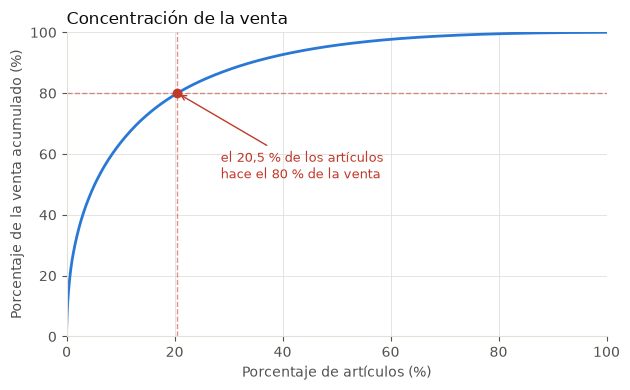

In [11]:
# Comprobacion de que se agrupa por el identificador unico y no por el nombre.
# Se hace antes de dibujar porque, si esto falla, la curva entera miente.
print("El identificador del artículo es `cod_articulo`, no la descripción:")
print(f"  códigos distintos       {num(a['cod_articulo'].nunique(), 0):>7}")
print(f"  descripciones distintas {num(a['descripcion'].nunique(), 0):>7}"
      f"   ← {num(a['descripcion'].nunique() - a['cod_articulo'].nunique(), 0)} de más")
print(f"  códigos con más de un nombre         {num(a.groupby('cod_articulo')['descripcion'].nunique().gt(1).sum(), 0):>6}"
      f"  (los parte el prefijo)")
print(f"  nombres repartidos en varios códigos {num(a.groupby('descripcion')['cod_articulo'].nunique().gt(1).sum(), 0):>6}"
      f"  (los junta el recorte)")

# Segundo control, este sobre el nombre: agrupado ya por codigo, la descripcion
# deberia ser la misma en toda la serie.
def sin_prefijo(texto):
    return re.sub(r"^\((?:P|FID|REG)\)\s*", "", str(texto)).strip()


def es_recorte(variantes):
    """True si las variantes son la misma cadena cortada a distinta longitud."""
    v = sorted(variantes, key=len)
    return all(v[-1].startswith(x[:max(4, len(x) - 2)]) for x in v[:-1])


limpio = a.assign(base=a["descripcion"].map(sin_prefijo)).groupby("cod_articulo")["base"]
cambian = int(a.groupby("cod_articulo")["descripcion"].nunique().gt(1).sum())
quedan = limpio.unique()[limpio.nunique() > 1]
recorte = quedan.map(es_recorte)
otro_producto = quedan[~recorte]

print("\nY el nombre, como control: ¿es el mismo artículo en toda la serie?")
print(f"  códigos que cambian de nombre           {num(cambian, 0):>7}")
print(f"    · lo explica el prefijo               {num(cambian - len(quedan), 0):>7}")
print(f"    · lo explica el recorte del nombre    {num(int(recorte.sum()), 0):>7}")
print(f"    · cambian de producto o de formato    {num(len(otro_producto), 0):>7}")
venta_ot = a.loc[a["cod_articulo"].isin(otro_producto.index), "total_venta"].sum()
print(f"      esos últimos pesan el "
      f"{num(100 * venta_ot / a['total_venta'].sum(), 2)} % de la venta de artículo")

orden = a.groupby("cod_articulo")["total_venta"].sum().sort_values(ascending=False)
acum = 100 * orden.cumsum() / orden.sum()
x = 100 * np.arange(1, len(orden) + 1) / len(orden)


def cuota(umbral):
    """Qué porcentaje del catálogo hace el `umbral` % de la venta."""
    return 100 * (int((acum <= umbral).sum()) + 1) / len(orden)


print()
for umbral in (50, 80, 90):
    print(f"  el {num(cuota(umbral), 1):>5} % de los artículos hace el {umbral} % de la venta")

pareto = cuota(80)

fig, ax = plt.subplots(figsize=(6.4, 4))
ax.plot(x, acum.values, color=AZUL, lw=2)

# El 80/20 se marca en la propia figura, que es el mensaje que hay que llevarse.
ax.axhline(80, color=ROJO, lw=1, ls="--", alpha=0.55)
ax.axvline(pareto, color=ROJO, lw=1, ls="--", alpha=0.55)
ax.plot([pareto], [80], marker="o", ms=6, color=ROJO, zorder=5)
ax.annotate(f"el {num(pareto, 1)} % de los artículos\nhace el 80 % de la venta",
            xy=(pareto, 80), xytext=(pareto + 8, 52), color=ROJO, fontsize=9,
            arrowprops=dict(arrowstyle="->", color=ROJO, lw=1))

ax.set_xlabel("Porcentaje de artículos (%)")
ax.set_ylabel("Porcentaje de la venta acumulado (%)")
ax.set_title("Concentración de la venta", color=TINTA, loc="left")
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
plt.tight_layout()
guardar(fig, "concentracion-abc")
plt.show()

Pareto casi al punto: el 20,5 % de los artículos vendidos
representa el 80 % de la facturación.

### Qué hay dentro de ese 20 % que hace el 80 % de la venta

**No son unos pocos productos estrella.** Es un surtido ancho, repartido por casi
toda la tienda: cada departamento aporta los suyos, y ninguno pesa por sí solo lo
suficiente como para explicar la concentración.

Abajo, los **tres artículos de más venta de cada departamento** dentro de ese
tramo, con el porcentaje de la facturación total que representa cada uno.

In [12]:
n80 = int((acum <= 80).sum()) + 1
tramo = orden.head(n80)

dpto_de = a.drop_duplicates("cod_articulo").set_index("cod_articulo")["departamento"]
sub = pd.DataFrame({"venta": tramo})
sub["dpto"] = dpto_de.reindex(sub.index)
sub["pct"] = 100 * sub["venta"] / orden.sum()

por_dpto = sub.groupby("dpto")["pct"].agg(["sum", "size"]).sort_values("sum", ascending=False)

print(f"{num(n80, 0)} artículos —el {num(100 * n80 / len(orden), 1)} % del catálogo— "
      f"hacen el 80 % de la venta,")
print(f"repartidos en {len(por_dpto)} departamentos. Los tres primeros de cada uno:\n")

for dpto, r in por_dpto.iterrows():
    print(f"{dpto}  ·  {num(r['sum'], 2)} % de la venta  ·  "
          f"{num(r['size'], 0)} artículos en el tramo")
    for cod, f in sub[sub["dpto"] == dpto].nlargest(3, "pct").iterrows():
        print(f"     {nombre[cod][:34]:<36}{num(f['pct'], 2):>6} %")
    print()

1.375 artículos —el 20,5 % del catálogo— hacen el 80 % de la venta,
repartidos en 13 departamentos. Los tres primeros de cada uno:

ULTRAMARINOS  ·  24,37 % de la venta  ·  559 artículos en el tramo
     PASTELES SURTIDO KG                   0,51 %
     ACEITE VIRGEN COOSUR 5 L              0,41 %
     ACEITE DE OLIVA VIRGEN                0,36 %

CARNICERIA  ·  13,19 % de la venta  ·  81 artículos en el tramo
     PECHUGA DE POLLO A                    1,14 %
     CARNE PICADA CERDO KG                 0,65 %
     POLLO NUTRAVE KG                      0,64 %

BEBIDAS  ·  10,85 % de la venta  ·  186 artículos en el tramo
     CERVEZA COVIRAN LATA                  1,09 %
     CERVEZA CLASICA                       0,33 %
     REFRESCO FRIO 33 CL                   0,32 %

FRUTAS Y VERDURAS  ·  9,06 % de la venta  ·  123 artículos en el tramo
     PLATANO SUPER EXTRA                   0,76 %
     BANANA EXTRA                          0,38 %
     PATATA ROJA BOLSA 3 KG                0,38 %



## 6. La serie del modelo, de un vistazo

Las 135 semanas completas en **euros corrientes**, para ver la evolución
general del negocio. Separar cuánto del crecimiento es precio y cuánto es
volumen se hace en los notebooks 02 y 03.

Sobre la línea van marcadas dos cosas:

- **El círculo negro**, en la semana del 6-12 de julio de 2026. Ahí la
  plataforma perdió **506 documentos y 5.751,82 €**, y la semana está
  reconstruida con los arqueos de caja. No señala una anomalía de la tienda:
  señala que **ese valor no sale entero de la plataforma**.
- **Los festivos**: en rojo los días que la tienda no abre y en amarillo los que
  abre solo de mañana. Cuáles son y con qué horario, justo debajo.

  guardada 01-serie-semanal.png / .svg


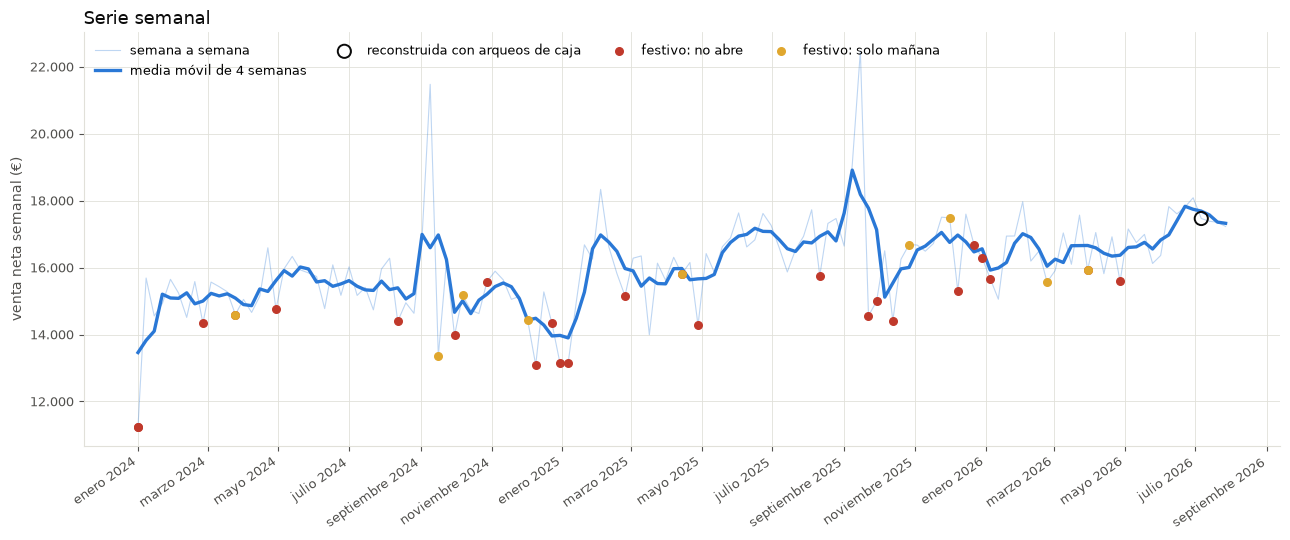

n = 135 semanas completas
media 16.038,89 €   desviación 1.411,18 €   CV 8,8 %
autocorrelación lag 1: +0,330   lag 52: +0,365


In [13]:
c = sem[sem["semana_completa"]].sort_values("periodo_inicio")

# La semana del 6-12 jul 2026 va en la línea como cualquier otra: está
# reconstruida con los arqueos de caja y es comparable.
VENTANA = 4   # semanas de la media movil: un mes, que es el plazo de la tienda

fig, ax = plt.subplots(figsize=(13, 5.5))
# El dato semanal se conserva de fondo: la media movil suaviza la lectura, no
# sustituye a la serie ni aplana los picos, que aqui son informacion (la semana
# previa a las fiestas locales es el maximo del año en los dos años).
ax.plot(c["periodo_inicio"], c["venta_neta"], color=AZUL, lw=0.8, alpha=0.30,
        label="semana a semana")
ax.plot(c["periodo_inicio"],
        c["venta_neta"].rolling(VENTANA, center=True, min_periods=1).mean(),
        color=AZUL, lw=2.4, label=f"media móvil de {VENTANA} semanas")
marcar_corregidas(ax, c, "venta_neta")

# Festivos entre semana: efecto de la Semana Santa y de los festivos (el
# tratamiento de festivos), con los horarios que confirmo la tienda.
marcar_festivos(ax, c, "venta_neta")

ax.set_ylabel("venta neta semanal (€)")
ax.set_title("Serie semanal", color=TINTA, loc="left", fontsize=13)
ax.legend(frameon=False, loc="upper left", fontsize=9, ncol=4)
eje_fechas_es(ax)
eje_miles(ax)
plt.tight_layout()
guardar(fig, "serie-semanal")
plt.show()

y = c["venta_neta"]
print(f"n = {len(y)} semanas completas")
print(f"media {num(y.mean())} €   desviación {num(y.std())} €   CV {num(100 * y.std() / y.mean(), 1)} %")
print(f"autocorrelación lag 1: {num(y.autocorr(1), 3, signo=True)}   lag 52: {num(y.autocorr(52), 3, signo=True)}")

# Banda de ruido: si la serie no tuviera estructura, la autocorrelación medida
# se movería al azar dentro de +-2/raiz(n). Lo que caiga fuera es señal.
banda = 2 / len(y) ** 0.5

Banda de ruido para n=135: ±0,172
el lag 52 (+0,365) la supera: hay ciclo anual, moderado.
El lag 52 se estima sobre 83 pares de semanas separadas por un año.

### Los festivos, y qué horario hace la tienda esos días

No cierra en todos. Hay festivos en que **no abre** y festivos en que **abre
solo de 9:30 a 13:30**, y la decisión es por fecha, no por tipo de fiesta. El
calendario lo facilitó la tienda y está en
[`festivos_tienda.csv`](../datos_externos/festivos_tienda.csv); las fiestas
locales se verificaron además contra el Boletín Oficial de la Junta de
Andalucía.

In [14]:
# Cuando son los festivos y que horario hace la tienda esos dias. Sale de
# festivos_tienda.csv, asi que si el fichero cambia esta tabla cambia sola.
HORARIO = {"cerrado": "no abre", "cerrado_fijo": "no abre",
           "manana": "9:30-13:30", "pendiente": "sin dato"}
LOCALES = ("Fiesta local", "Primera fiesta local", "Segunda fiesta local")

fest = pd.read_csv("../datos_externos/festivos_tienda.csv", parse_dates=["fecha"])
v = fest[(fest["fecha"] >= c["periodo_inicio"].min())
         & (fest["fecha"] <= c["periodo_fin"].max())].sort_values("fecha").copy()

# Las dos locales cambian de nombre segun el ano, asi que se numeran por orden
# dentro de cada ano para que la tabla tenga una fila por fiesta y no se mezclen.
es_local = v["nombre"].isin(LOCALES)
v["fiesta"] = v["nombre"]
v.loc[es_local, "fiesta"] = (
    "Fiesta local " + (v[es_local].groupby(v["fecha"].dt.year).cumcount() + 1).astype(str)
)
v["año"] = v["fecha"].dt.year
v["celda"] = v["fecha"].dt.strftime("%d/%m") + "  " + v["apertura"].map(HORARIO)

tabla = (v.pivot_table(index="fiesta", columns="año", values="celda", aggfunc="first")
          .reindex(v["fiesta"].unique()))

ANCHO = 22
print(f"{'festivo':<26}" + "".join(f"{a:<{ANCHO}}" for a in tabla.columns))
print("-" * (26 + ANCHO * len(tabla.columns)))
for fiesta, r in tabla.iterrows():
    print(f"{fiesta[:25]:<26}"
          + "".join(f"{(x if isinstance(x, str) else '—'):<{ANCHO}}" for x in r))

cerrado = int(v["apertura"].isin(["cerrado", "cerrado_fijo"]).sum())
manana = int((v["apertura"] == "manana").sum())
sabados = int(((v["apertura"] == "manana") & (v["dia_semana"] == "sábado")).sum())

festivo                   2024                  2025                  2026                  
--------------------------------------------------------------------------------------------
Año Nuevo                 01/01  no abre        01/01  no abre        01/01  no abre        
Epifanía del Señor        06/01  no abre        06/01  no abre        06/01  no abre        
Día de Andalucía          28/02  no abre        28/02  no abre        28/02  9:30-13:30     
Jueves Santo              28/03  9:30-13:30     17/04  9:30-13:30     02/04  9:30-13:30     
Viernes Santo             29/03  no abre        18/04  no abre        03/04  no abre        
Día del Trabajo           01/05  no abre        01/05  no abre        01/05  no abre        
Asunción de la Virgen     15/08  no abre        15/08  no abre        —                     
Fiesta local 1            16/09  9:30-13:30     22/09  no abre        —                     
Fiesta local 2            30/09  no abre        29/09  no abre        

34 festivos en la ventana: en 25 no abre y en 9 abre solo de mañana.
De esos 9, 4 caen en sábado, día en que la tienda ya cerraba a las 14:00. Así que
un festivo de mañana cuesta media jornada entre semana y casi nada en sábado:
por eso, al modelar, el festivo se cuenta en horas y no como una etiqueta.

## 7. Tickets, fidelización y cupones — el resto del cierre Z

La serie semanal no es solo `venta_neta`: trae cuántos tickets hubo, qué parte
de la venta fue con tarjeta de fidelización y cuántos cupones se emitieron y
se canjearon. Ninguna de estas columnas se había mirado todavía.

In [15]:
cols = ["venta_neta", "tickets", "pct_tickets_fidelizados",
        "pct_venta_fidelizada", "cupones_emitidos", "cupones_redimidos"]

print("Ficha técnica, 135 semanas completas\n")
print(c[cols].describe().round(2).to_string())
print(f"\nnulos: {int(c[cols].isna().sum().sum())} (ninguna columna tiene huecos)")


Ficha técnica, 135 semanas completas

       venta_neta  tickets  pct_tickets_fidelizados  pct_venta_fidelizada  cupones_emitidos  cupones_redimidos
count      135,00   135,00                   135,00                135,00            135,00             135,00
mean    16.038,89 1.436,40                    30,33                 46,58            436,23              29,47
std      1.411,18   130,73                     2,40                  3,07             50,72              11,44
min     11.235,49   972,00                    23,16                 36,23            244,00               8,00
25%     15.161,10 1.353,50                    28,81                 45,10            405,00              22,00
50%     16.021,51 1.454,00                    30,49                 46,97            435,00              28,00
75%     16.787,60 1.528,50                    31,90                 48,76            474,00              35,00
max     22.466,66 1.743,00                    36,97                 53,56 

  guardada 01-tickets-y-ticket-medio.png / .svg


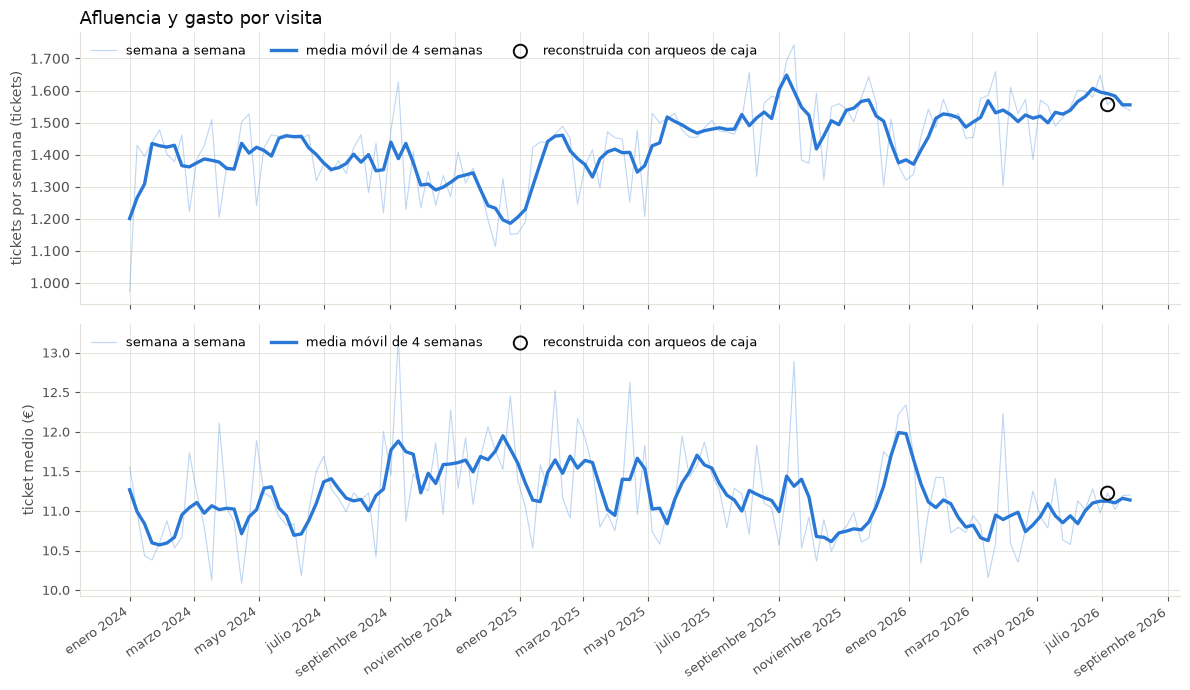

In [16]:
# Afluencia y gasto por visita, en una sola figura y en dos paneles. No se usa
# un segundo eje Y: son magnitudes distintas -numero de tickets y
# euros- y superponerlas haria que sus cruces parecieran significar algo.
VENTANA = 4   # semanas de la media movil: un mes, que es como decide la tienda

c["ticket_medio"] = c["venta_neta"] / c["tickets"]
suave = lambda s: s.rolling(VENTANA, center=True, min_periods=1).mean()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

for ax, col, etiqueta, unidad in [
    (ax1, "tickets", "tickets por semana", "tickets"),
    (ax2, "ticket_medio", "ticket medio", "€"),
]:
    # El dato semanal se conserva de fondo: la media movil suaviza la lectura,
    # no sustituye a la serie ni oculta los picos.
    ax.plot(c["periodo_inicio"], c[col], color=AZUL, lw=0.8, alpha=0.30,
            label="semana a semana")
    ax.plot(c["periodo_inicio"], suave(c[col]), color=AZUL, lw=2.4,
            label=f"media móvil de {VENTANA} semanas")
    marcar_corregidas(ax, c, col)
    ax.set_ylabel(f"{etiqueta} ({unidad})")
    ax.legend(frameon=False, loc="upper left", fontsize=9, ncol=3)

ax1.set_title("Afluencia y gasto por visita", color=TINTA,
              loc="left", fontsize=13)
eje_miles(ax1)
eje_fechas_es(ax2)
plt.tight_layout()
guardar(fig, "tickets-y-ticket-medio")
plt.show()

  guardada 01-venta-fidelizada-semanal.png / .svg


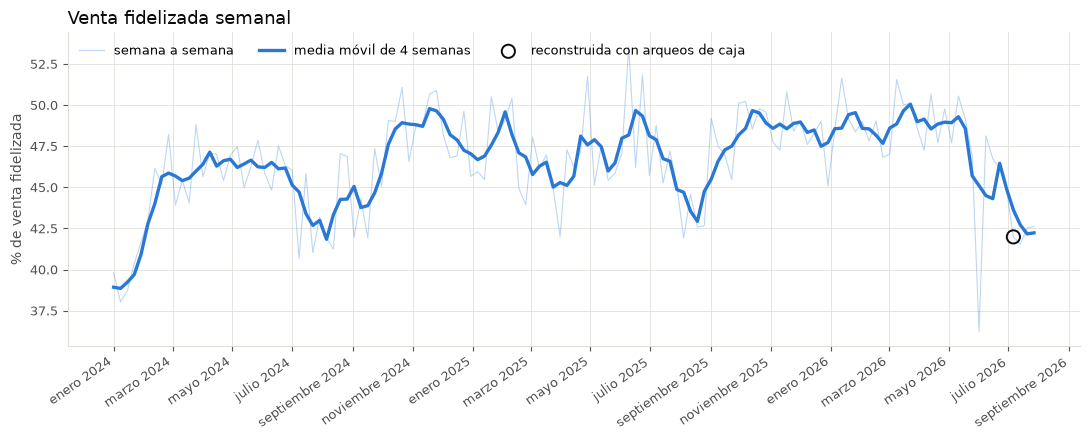

In [17]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(c["periodo_inicio"], c["pct_venta_fidelizada"], color=AZUL, lw=0.8, alpha=0.30,
        label="semana a semana")
ax.plot(c["periodo_inicio"], suave(c["pct_venta_fidelizada"]), color=AZUL, lw=2.4,
        label=f"media móvil de {VENTANA} semanas")
marcar_corregidas(ax, c, "pct_venta_fidelizada")

ax.set_ylabel("% de venta fidelizada")
ax.set_title("Venta fidelizada semanal", color=TINTA, loc="left", fontsize=13)
ax.legend(frameon=False, loc="upper left", fontsize=9, ncol=3)
eje_fechas_es(ax)
plt.tight_layout()
guardar(fig, "venta-fidelizada-semanal")
plt.show()

In [18]:
pendiente_tickets = np.polyfit(np.arange(len(c)), c["tickets"], 1)[0]
pendiente_ticket_medio = np.polyfit(np.arange(len(c)), c["ticket_medio"], 1)[0]

print(f"ticket medio: {num(c['ticket_medio'].mean())} € "
      f"(entre {num(c['ticket_medio'].min())} y {num(c['ticket_medio'].max())})")
print(f"correlación venta_neta ~ tickets     : {num(c['venta_neta'].corr(c['tickets']), 3, signo=True)}")
print(f"correlación venta_neta ~ ticket_medio: {num(c['venta_neta'].corr(c['ticket_medio']), 3, signo=True)}")
print(f"\npendiente tickets      : {num(pendiente_tickets, 2, signo=True)} tickets/semana")
print(f"pendiente ticket_medio : {num(pendiente_ticket_medio, 4, signo=True)} €/semana")

ticket medio: 11,19 € (entre 10,08 y 13,21)
correlación venta_neta ~ tickets     : +0,830
correlación venta_neta ~ ticket_medio: +0,183

pendiente tickets      : +1,69 tickets/semana
pendiente ticket_medio : -0,0009 €/semana


El crecimiento de la venta viene de más tickets (más afluencia),
no de un ticket medio mayor: el ticket apenas se mueve.

In [19]:
# Fidelizacion y cupones, por ano.
g = c.groupby(c["periodo_inicio"].dt.year)

resumen = pd.DataFrame({
    "venta fidelizada (%)": g["pct_venta_fidelizada"].mean(),
    "cupones emitidos": g["cupones_emitidos"].sum(),
    "cupones canjeados": g["cupones_redimidos"].sum(),
    "redención (%)": 100 * g["cupones_redimidos"].sum() / g["cupones_emitidos"].sum(),
    "semanas": g.size(),
})
resumen.loc["total"] = [
    c["pct_venta_fidelizada"].mean(),
    c["cupones_emitidos"].sum(),
    c["cupones_redimidos"].sum(),
    100 * c["cupones_redimidos"].sum() / c["cupones_emitidos"].sum(),
    len(c),
]
resumen.index.name = "año"

# Se formatea a mano porque el formato global de pandas pone dos decimales a
# todo, y los cupones y las semanas son recuentos, no importes.
DECIMALES = {"venta fidelizada (%)": 2, "cupones emitidos": 0, "cupones canjeados": 0,
             "redención (%)": 2, "semanas": 0}
display(resumen.apply(lambda col: col.map(lambda x: num(x, DECIMALES[col.name]))))

,venta fidelizada (%),cupones emitidos,cupones canjeados,redención (%),semanas
año,,,,,
2024,"45,53",21.091,1.367,"6,48",53
2025,"47,24",23.469,1.421,"6,05",52
2026,"47,27",14.331,1.190,"8,30",30
total,"46,58",58.891,3.978,"6,75",135


Casi la mitad de la venta pasa por la tarjeta del Club Familia, y la
proporción sube poco pero sube. Los cupones, en cambio, se canjean poco:
de cada 100 emitidos vuelven menos de 7 — aunque 2026 va mejor que los
dos años anteriores.

## 8. Composición por departamento

Los dos informes reparten la venta por departamento, y aquí se usa **el diario
de ventas por artículo** por una razón concreta: **es el único que da el
importe sin IVA**. El cierre Z solo declara el importe con impuestos y no dice
qué tipo lleva cada departamento, así que de ahí no se puede sacar el neto.

De paso se evita otro problema: **el cierre Z corta los nombres a 16
caracteres** —`CHARCUTERIA CORT` es *CHARCUTERIA CORTE*, `L.S CARNICO Y SA` es
*L.S CARNICO Y SALAZONES*, y así con siete de los dieciocho—, mientras que el
diario por artículo los da enteros.

La contrapartida es la ventana: **31 meses completos (2024-01 → 2026-07)** en
vez de las 135 semanas. **El reparto no depende de cuál se mire**: los dos
totales cuadran al 0,05 % —2.166.276 € netos del diario por artículo frente a
2.165.251 € del cierre Z— y ningún departamento se mueve más de 1,2 puntos
porcentuales entre una fuente y otra.

**Cuatro de los dieciocho departamentos son residuales.** `CARNICERIA L.S`,
`PESCADO Y MARISCO`, `TEXTIL` y `L.S CARNICO Y SALAZONES` suman **224,55 € en
31 meses** —un 0,01 % del total—. Se agrupan en `OTROS` para que el gráfico se
lea, pero **no se descartan**: el detalle se imprime debajo.

*`L.S` es «libre servicio»*: el mismo género envasado en lineal en vez de
despachado en mostrador. De ahí las parejas `CARNICERIA` / `CARNICERIA L.S` y
`CHARCUTERIA CORTE` / `CHARCUTERIA L.S`.

  guardada 01-composicion-departamentos.png / .svg


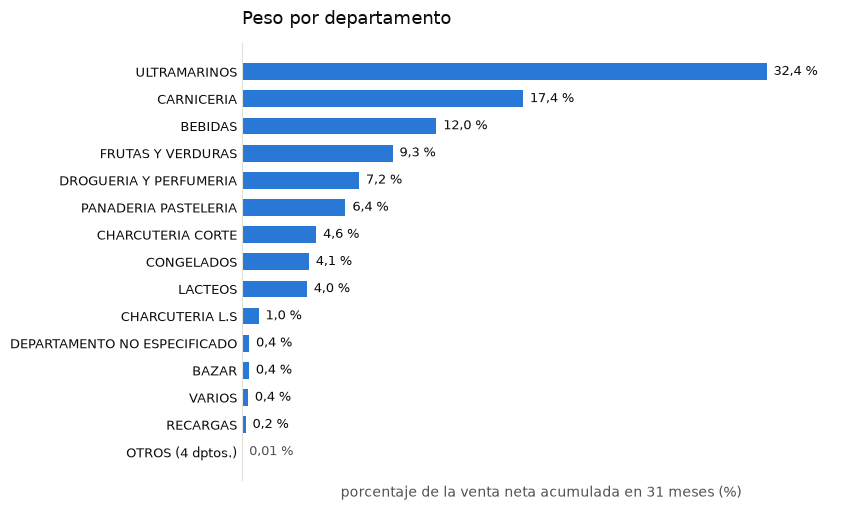

18 departamentos distintos en 31 meses
total de la ventana: 2.166.275,77 € Sin IVA

  ULTRAMARINOS                    32,44 %     702.824,39 €
  CARNICERIA                      17,38 %     376.470,49 €
  BEBIDAS                         12,02 %     260.393,51 €
  FRUTAS Y VERDURAS                9,31 %     201.677,25 €
  DROGUERIA Y PERFUMERIA           7,24 %     156.740,99 €
  PANADERIA PASTELERIA             6,40 %     138.627,83 €

los 6 primeros hacen el 84,8 % de la venta.

Agrupados en otros — bajo el 0.1 % de la venta Y presentes en menos de la mitad de los meses (224,55 € entre los 4):
  CARNICERIA L.S                   161,14 €   en  7 de 31 meses
  PESCADO Y MARISCO                 45,53 €   en  2 de 31 meses
  TEXTIL                            15,45 €   en  1 de 31 meses
  L.S CARNICO Y SALAZONES            2,43 €   en  1 de 31 meses


In [20]:
# Reparto por departamento sin IVA, desde el diario de ventas por articulo.
peso = art.groupby("departamento")["total_venta"].sum().sort_values(ascending=False)
total = peso.sum()
meses_con = art[art["total_venta"] != 0].groupby("departamento")["periodo_inicio"].nunique()
n_meses = art["periodo_inicio"].nunique()

UMBRAL_OTROS = 0.1

# "Vestigial" es poco dinero Y poca presencia, las dos condiciones a la vez: un
# departamento puede sumar casi cero porque apenas se usa o porque se compensa
# solo, y no es lo mismo.
vestigiales = peso[(100 * peso / total < UMBRAL_OTROS)
                   & (meses_con.reindex(peso.index).fillna(0) < 0.5 * n_meses)]

peso_plot = peso.drop(vestigiales.index)
if len(vestigiales):
    peso_plot[f"OTROS ({len(vestigiales)} dptos.)"] = vestigiales.sum()

# Porcentaje de la venta neta acumulada en los 31 meses.
pct = (100 * peso_plot / total).sort_values()

# Una sola serie, un solo color.
colores = [GRID if n.startswith("OTROS") else AZUL for n in pct.index]

fig, ax = plt.subplots(figsize=(8.6, 5.2))
ax.barh(pct.index, pct.values, color=colores, height=0.62)

# Con el valor al final de cada barra sobra el eje: las etiquetas directas van
# antes que las lineas de rejilla, y la rejilla antes que un segundo eje.
for y, (nombre, v) in enumerate(pct.items()):
    # Un decimal basta salvo en los que redondearian a 0,0 sin ser cero:
    # escribir "0,0 %" donde hay 224 EUR seria mentir por redondeo.
    etiqueta = f"{num(v, 1 if v >= 0.1 else 2)} %"
    ax.annotate(etiqueta, (v, y), xytext=(5, 0), textcoords="offset points",
                va="center", fontsize=9,
                color=TINTA_SEC if nombre.startswith("OTROS") else TINTA)

ax.set_xlim(0, pct.max() * 1.14)
ax.set_xlabel(f"porcentaje de la venta neta acumulada en {n_meses} meses (%)",
              color=TINTA_SEC)
ax.set_title("Peso por departamento", color=TINTA, loc="left",
             fontsize=13, pad=14)

# Rejilla y ejes recesivos: aqui el dato es la barra, no la caja que la rodea.
ax.grid(False)
ax.set_xticks([])
for lado in ("top", "right", "bottom"):
    ax.spines[lado].set_visible(False)
ax.spines["left"].set_color(GRID)
ax.tick_params(axis="y", length=0, labelsize=9.5, colors=TINTA)

plt.tight_layout()
guardar(fig, "composicion-departamentos")
plt.show()

print(f"{art['departamento'].nunique()} departamentos distintos en {n_meses} meses")
print(f"total de la ventana: {num(total)} € Sin IVA\n")
for k, v in peso.head(6).items():
    print(f"  {k:<30} {num(100 * v / total, 2):>6} %   {num(v):>12} €")
print(f"\nlos 6 primeros hacen el {num(100 * peso.head(6).sum() / total, 1)} % de la venta.")

# Detalle de lo agrupado: son reales (verificados en los PDF originales), pero
# La tienda apenas usa esos departamentos.
print(f"\nAgrupados en otros — bajo el {UMBRAL_OTROS} % de la venta Y presentes en "
      f"menos de la mitad de los meses "
      f"({num(vestigiales.sum())} € entre los {len(vestigiales)}):")
for k, v in vestigiales.items():
    print(f"  {k:<30} {num(v):>8} €   en {meses_con[k]:>2} de {n_meses} meses")

# Departamento no especificado no significa lo mismo en las dos fuentes, y
# conviene no arrastrar la lectura de una a la otra.
dne = "DEPARTAMENTO NO ESPECIFICADO"
a_dne = art[art["departamento"] == dne]

Departamento no especificado: 9.448,47 € (0,44 %), en 31 de 31 meses.
Aqui son 147 articulos corrientes sin departamento
asignado en su ficha (dip dip, hot dogs, bollisol mini), no un cajon de
descuadres: los 31 meses cierra en positivo. En el cierre Z ese mismo
nombre es el cajón donde el TPV mete las devoluciones: cierra en negativo
27 de las 135 semanas y por eso su saldo sale mucho más pequeño. Misma
etiqueta, contenido distinto — ver el cuadre de más abajo.

### Estacionalidad de los cuatro departamentos principales

**Esta figura va con IVA y en euros corrientes**, y conviene saberlo antes de
leerla:

- **Con IVA, porque no hay alternativa.** El detalle **semanal** por
  departamento solo lo da el cierre Z, que no permite separar los impuestos. Se
  prefiere la resolución semanal al importe neto.
- **En euros corrientes**, así que incluye la subida de precios de los 2,6 años,
  no solo la evolución del volumen.

Se dibuja como una línea sobre el eje del tiempo, y no como medias por mes,
por dos motivos: **26 de las 135 semanas cruzan de mes**, y los meses no tienen
el mismo número de semanas (**14 en marzo frente a 8 en agosto, octubre y
noviembre**). Así todas las semanas pesan lo mismo. La línea gruesa es una
media móvil de 5 semanas; el ratio de debajo sí agrupa por mes y se calcula
sobre el dato sin suavizar.

  guardada 01-estacionalidad-departamentos.png / .svg


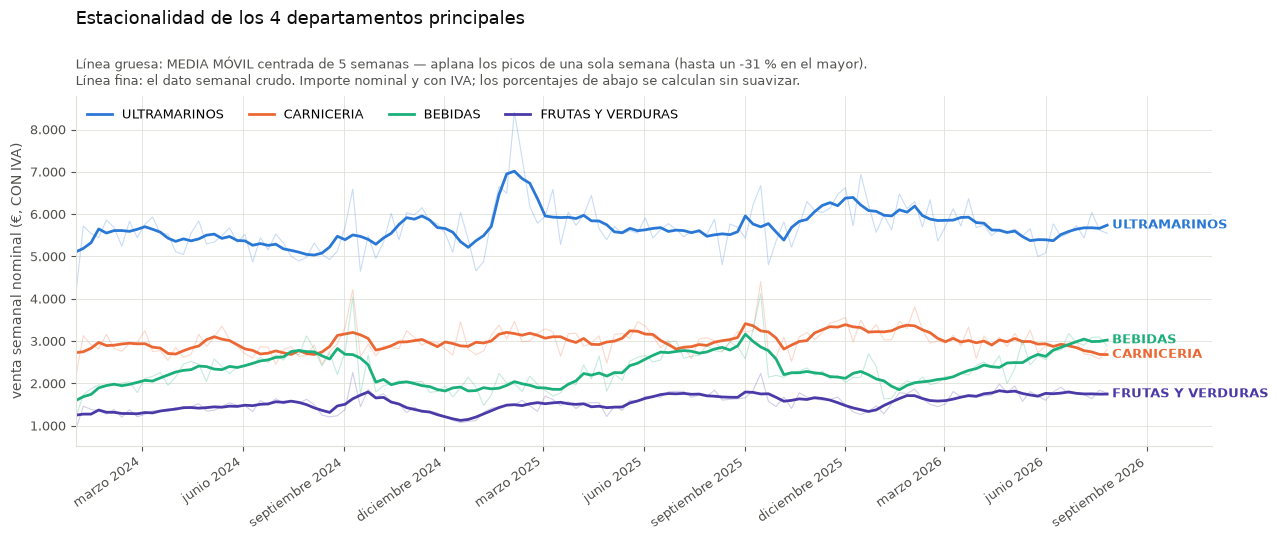

ratio verano (jun-ago) / invierno (dic-feb), sobre venta nominal:

  ULTRAMARINOS           -8,0 %
  CARNICERIA             -7,5 %
  BEBIDAS               +39,4 %
  FRUTAS Y VERDURAS     +17,2 %


In [21]:
# Paleta categórica para los 4 departamentos: slots 1, 2, 3 y 7 de la paleta de
# referencia.
SERIES = {
    "ULTRAMARINOS":      "#2a78d6",
    "CARNICERIA":        "#eb6834",
    "BEBIDAS":           "#1baf7a",
    "FRUTAS Y VERDURAS": "#4a3aa7",
}
VENTANA = 5   # semanas de la media móvil centrada

# El cierre Z corta los nombres a 16 caracteres (charcuteria cort).
LARGOS = sorted(art["departamento"].dropna().unique())


def nombre_entero(corto):
    if corto in LARGOS:
        return corto
    candidatos = [x for x in LARGOS if x.startswith(corto)]
    return candidatos[0] if len(candidatos) == 1 else corto


# El reparto semanal por departamento solo lo da el cierre Z, y lo da con IVA.
dep = pd.read_parquet("../datos_limpio/serie_semanal_departamentos.parquet")

# Los 4 mayores se toman del propio cierre Z, no del reparto neto de arriba:
# esta figura es suya y las dos fuentes podrian no coincidir. Coinciden.
d = dep.copy()
d["departamento"] = d["departamento"].map(nombre_entero)
top4 = (d.groupby("departamento")["importe"].sum()
         .sort_values(ascending=False).head(4).index.tolist())
assert set(top4) == set(SERIES), f"los 4 mayores han cambiado: {top4}"

# Importe nominal y con IVA: es lo que declara el cierre Z, y en este notebook
# no se deflacta nada (ver la celda de arriba).
serie = (d[d["departamento"].isin(top4)]
         .pivot_table(index="periodo_inicio", columns="departamento", values="importe")
         .sort_index())

# Ya no se anula ninguna semana: la del 6-12 jul 2026 está reconstruida con
# los arqueos de caja y entra en la media móvil como otra más.
suave = serie.rolling(VENTANA, center=True, min_periods=3).mean()

fig, ax = plt.subplots(figsize=(13, 5.5))

# Aquí no se marca la semana reconstruida con los arqueos de caja, a diferencia
# de las figuras del punto 6 y 7.

for depto, color in SERIES.items():
    ax.plot(serie.index, serie[depto], color=color, lw=0.8, alpha=0.25)
    ax.plot(suave.index, suave[depto], color=color, lw=2, label=depto)

# Etiqueta directa al final de cada línea, separadas si se pisan: la identidad
# no puede depender solo del color (uno de los cuatro se queda en 2,74:1 de
# contraste sobre el fondo, por debajo del 3:1).
ultimo = suave.index[suave.notna().any(axis=1)][-1]
alturas = suave.loc[ultimo].sort_values()
minimo = 0.045 * (serie.max().max() - serie.min().min())
colocadas, previa = {}, -np.inf
for depto, y in alturas.items():
    previa = max(y, previa + minimo)
    colocadas[depto] = previa
for depto, y in colocadas.items():
    ax.annotate(f" {depto}", (ultimo, y), color=SERIES[depto],
                fontsize=9, va="center", fontweight="bold")

ax.set_ylabel("venta semanal nominal (€, CON IVA)")

# Cuanto aplana la media movil el pico mas alto de cada serie: se mide en vez
# de teclearse, porque es la cifra que impide leer la linea gruesa como si
# fuera el dato.
aplana = min(suave[x][serie[x].idxmax()] / serie[x].max() - 1 for x in SERIES)

# Titulo y aviso en dos niveles: el suavizado no puede leerse como si fuera el
# dato.
ax.set_title("Estacionalidad de los 4 departamentos principales",
             color=TINTA, loc="left", fontsize=13, pad=52)
ax.text(0, 1.02,
        f"Línea gruesa: MEDIA MÓVIL centrada de {VENTANA} semanas — aplana los picos "
        f"de una sola semana (hasta un {num(100 * aplana, 0, signo=True)} % en el mayor).\n"
        "Línea fina: el dato semanal crudo. Importe nominal y con IVA; los "
        "porcentajes de abajo se calculan sin suavizar.",
        transform=ax.transAxes, color=TINTA_SEC, fontsize=9, va="bottom")

ax.legend(frameon=False, loc="upper left", fontsize=9, ncol=4)
ax.set_xlim(serie.index.min(), serie.index.max() + pd.Timedelta(days=95))
eje_fechas_es(ax, intervalo_meses=3)
eje_miles(ax)
plt.tight_layout()
guardar(fig, "estacionalidad-departamentos")
plt.show()

# El ratio verano/invierno se mide sobre el dato crudo, sin suavizar: la media
# móvil es para leer el gráfico, no para calcular.
mes = serie.groupby(serie.index.month).mean()
ratios = {x: mes.loc[[6, 7, 8], x].mean() / mes.loc[[12, 1, 2], x].mean() - 1
          for x in SERIES}
print("ratio verano (jun-ago) / invierno (dic-feb), sobre venta nominal:\n")
for depto, r in ratios.items():
    print(f"  {depto:<20} {num(100 * r, 1, signo=True):>6} %")

# La lectura se deriva de los ratios en vez de teclearse: si algun dia un
# departamento cambia de signo, cambia la frase con el.
sube = dict(sorted({k: v for k, v in ratios.items() if v > 0}.items(),
                   key=lambda x: -x[1]))
baja = dict(sorted({k: v for k, v in ratios.items() if v <= 0}.items(),
                   key=lambda x: x[1]))
lider = next(iter(sube))

# Hasta donde llega ese verano: el adelantamiento se mide, no se afirma.
rival = min(baja, key=lambda x: mes[x].mean())      # el contraestacional mas cercano
cruces = serie[serie[lider] > serie[rival]]
años = sorted({int(a) for a in cruces.index.year})
meses_pico = mes.index[mes[lider] > mes[rival]].tolist()

Bebidas llega a adelantar a carniceria en 13 de las 135 semanas,
repartidas de mayo a septiembre y presentes en los 3 años de la serie.
En media mensual solo lo supera en julio: el adelantamiento
es de semanas sueltas, no de una temporada entera.

Hay 2 departamentos estacionales y 2 contraestacionales. Bebidas es el más
estacional con diferencia (+39 %), y frutas y verduras sube un +17 %:
moderado, no despreciable.
Ultramarinos y carniceria venden menos en verano (-8 % y -7 %).

In [22]:
suma_dep = dep.groupby("periodo_inicio")["importe"].sum().reset_index(name="suma_departamentos")
chk = sem[["periodo_inicio", "venta_total"]].merge(suma_dep, on="periodo_inicio")
chk["desvio"] = (chk["suma_departamentos"] - chk["venta_total"]).round(2)

descuadran = chk[chk["desvio"].abs() > 0.005]
print(f"semanas que no cuadran al céntimo: {len(descuadran)} de {len(chk)}\n")
print(descuadran.to_string(index=False))

semanas que no cuadran al céntimo: 2 de 135

periodo_inicio  venta_total  suma_departamentos  desvio
    2025-10-27    18.363,20           18.363,19   -0,01
    2026-04-06    18.778,47           18.780,52    2,05


El descuadre se debía a un fallo del programa de lectura, ya corregido, no del negocio.
El regex de la fila de departamento admitía signo en el importe pero no
en el porcentaje, así que las filas con los dos en negativo se
descartaban en silencio. 27 de las 28 semanas del descuadre eran eso;
las otras dos son 2,05 € y 1 céntimo, residuo sin patrón.

## 9. Estacionalidad mensual

**El cierre Z semanal no trae desglose por día**, así que aquí no se puede
aislar un efecto por día de la semana. Lo que sí hay son 135 semanas para ver
el patrón mes a mes, **en euros corrientes y sin IVA**.

### Cómo se lee la figura, y por qué los meses no pesan igual

Cada caja resume **las semanas que cayeron en ese mes** a lo largo de los 2,6
años. La línea roja es la mediana —la semana típica—, la caja es el 50 %
central y los círculos son semanas atípicas. Importa tanto **dónde** está cada
caja (el nivel del mes) como **cómo de alta** es (lo predecible que es).

**El número de semanas de cada mes va impreso bajo su nombre, y va de 8 a 14.**
La desigualdad no es aleatoria:

| Meses | Años que cubren |
|---|---|
| enero → julio | **3** (2024, 2025, 2026) |
| agosto → diciembre | **2** (2024, 2025) |

Como el importe va en euros corrientes, eso se nota. Comparando la mediana de
cada mes con las 135 semanas frente a solo los años completos (2024 y 2025, 104
semanas), **los siete meses con datos de 2026 suben**: la venta crece unos
**918 € al año** y esos meses llevan dentro el tramo más reciente de la serie.

**Por eso esta figura sirve para el nivel y la dispersión, no como índice
estacional.** Lo que se mantiene con los dos cortes:

- **Junio es el mes de mediana más alta.**
- **Septiembre es el más disperso y mayo el más regular.**

Lo que **no** se mantiene es el orden del medio: julio cae del 2.º puesto al 6.º
y abril del 8.º al 11.º según el corte. Se conservan las 135 semanas, porque
recortar a años completos tiraría el 22 % de los datos sin resolver el
problema de fondo, que se resuelve deflactando.

  guardada 01-estacionalidad-mensual.png / .svg


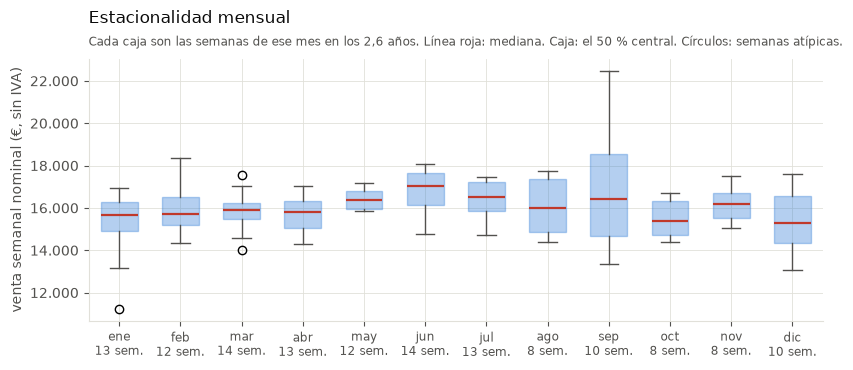

                mean    median      std  n_semanas
mes                                               
enero      15.210,00 15.649,60 1.594,40         13
febrero    15.986,50 15.704,30 1.230,70         12
marzo      15.842,00 15.919,00   902,80         14
abril      15.701,20 15.807,30   887,20         13
mayo       16.406,50 16.375,70   469,30         12
junio      16.815,00 17.046,10 1.058,70         14
julio      16.358,00 16.528,80   908,50         13
agosto     16.066,20 16.018,60 1.337,70          8
septiembre 16.961,10 16.400,80 3.116,50         10
octubre    15.494,40 15.376,10   897,70          8
noviembre  16.138,30 16.191,40   854,40          8
diciembre  15.363,20 15.288,00 1.638,40         10

media más alta:   septiembre    16.961 €
media más baja:   enero         15.210 €
más impredecible: septiembre  desviación  3.117 €
más regular:      mayo        desviación    469 €

sesgo por incluir 2026 (mediana con 135 semanas menos mediana con solo 2024+2025):
  enero         +67

In [23]:
# Venta nominal y neta de IVA: en este notebook no se deflacta nada, el efecto
# del IPC es cosa del notebook 02.
COL = "venta_neta"

c["mes"] = c["periodo_inicio"].dt.month
por_mes = [c.loc[c["mes"] == m, COL].values for m in range(1, 13)]
n_por_mes = [len(x) for x in por_mes]

# Nombre abreviado + cuántas semanas hay detrás de cada caja.
MESES_CORTOS = [m[:3] for m in MESES_ES]
etiquetas = [f"{MESES_CORTOS[m - 1]}\n{n} sem." for m, n in enumerate(n_por_mes, 1)]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.boxplot(por_mes, positions=range(1, 13), widths=0.6, patch_artist=True,
           boxprops=dict(facecolor=AZUL, alpha=0.35, color=AZUL),
           medianprops=dict(color=ROJO, lw=1.6),
           whiskerprops=dict(color=TINTA_SEC), capprops=dict(color=TINTA_SEC))
ax.set_xticks(range(1, 13))
ax.set_xticklabels(etiquetas, fontsize=8.5)
eje_miles(ax)
ax.set_ylabel("venta semanal nominal (€, sin IVA)")
ax.set_title("Estacionalidad mensual", color=TINTA, loc="left", pad=26)
ax.text(0, 1.04,
        "Cada caja son las semanas de ese mes en los 2,6 años. Línea roja: mediana. "
        "Caja: el 50 % central. Círculos: semanas atípicas.",
        transform=ax.transAxes, color=TINTA_SEC, fontsize=8.5, va="bottom")
plt.tight_layout()
guardar(fig, "estacionalidad-mensual")
plt.show()

resumen = c.groupby("mes")[COL].agg(["mean", "median", "std"])
resumen["n_semanas"] = n_por_mes
resumen.index = [MESES_ES[m - 1] for m in resumen.index]
resumen.index.name = "mes"
print(resumen.round(1).to_string())

print(f"\nmedia más alta:   {resumen['mean'].idxmax():<11} "
      f"{num(resumen['mean'].max(), 0):>8} €")
print(f"media más baja:   {resumen['mean'].idxmin():<11} "
      f"{num(resumen['mean'].min(), 0):>8} €")
print(f"más impredecible: {resumen['std'].idxmax():<11} "
      f"desviación {num(resumen['std'].max(), 0):>6} €")
print(f"más regular:      {resumen['std'].idxmin():<11} "
      f"desviación {num(resumen['std'].min(), 0):>6} €")

# La media y la mediana no coinciden en septiembre, y esa discrepancia es el
# hallazgo, no un detalle: la media la levantan los picos de las fiestas
# locales, la mediana no.
med = resumen["median"]
alto_media, alto_mediana = resumen["mean"].idxmax(), med.idxmax()

# Nivel y dispersion, medidos y no tecleados: el hallazgo es que el primero
# apenas se mueve y la segunda muchisimo.
lo, hi = resumen["mean"].min(), resumen["mean"].max()
veces = resumen["std"].max() / resumen["std"].min()

# Comprobación del sesgo de cobertura: enero-julio tienen 3 años y
# agosto-diciembre solo 2, así que la primera mitad del año lleva un trozo de
# 2026 que la segunda no.
completos = c[c["periodo_inicio"].dt.year < 2026]
med_todo = c.groupby("mes")[COL].median()
med_comp = completos.groupby("mes")[COL].median()
sesgo = (med_todo - med_comp).dropna()
sesgo_pct = (100 * sesgo / med_comp).dropna()
# Agosto-diciembre no reciben ninguna semana de 2026, asi que su sesgo es cero,
# no nulo: hay que dejarlos fuera del recuento o parece que ellos tambien se mueven.
afectados = sesgo_pct[sesgo != 0]

print("\nsesgo por incluir 2026 (mediana con 135 semanas menos mediana con "
      "solo 2024+2025):")
for m in range(1, 8):
    print(f"  {MESES_ES[m - 1]:<10} {num(sesgo[m], 0, signo=True):>7} €   "
          f"({num(sesgo_pct[m], 1, signo=True)} %)")
print("  agosto-diciembre  sin cambio: no hay semanas de 2026 que añadir")

peor = afectados.abs().idxmax()

# Que aguanta y que no si se cambia de corte. El orden se compara entero en vez
# de fiarse de los dos primeros puestos.
orden_todo = [MESES_ES[m - 1] for m in med_todo.sort_values(ascending=False).index]
orden_comp = [MESES_ES[m - 1] for m in med_comp.sort_values(ascending=False).index]
movimientos = sorted(((abs(orden_todo.index(x) - orden_comp.index(x)), x)
                      for x in orden_todo), reverse=True)
salto, quien = movimientos[0]
std_comp = completos.groupby("mes")[COL].std()


# Se conservan las 135 semanas: recortar tiraria el 23 % de los datos y dejaria
# todas las cajas peor estimadas, no solo las cinco afectadas.
n_comp = completos.groupby("mes").size()

La media más alta (septiembre) y la mediana más alta (junio) no son el mismo mes.
En septiembre la media (16.961 €) va 560 € por encima de su mediana (16.401 €):
la levantan un par de semanas de pico, no el mes entero. El boxplot
dibuja medianas, así que es la mediana la que hay que leer en él.

Aguantan los dos cortes: la mediana más alta es de junio con las 135
semanas y de junio con solo los años completos; y el mes más
disperso es septiembre en los dos, el más regular mayo.
No aguanta el orden del medio: julio se mueve 4 puestos entre un
corte y el otro, así que esta figura no sirve para ordenar los meses.

Se conservan las 135 semanas: recortar a años completos tiraría
30 (22 % de los datos) y dejaría todas las cajas con n de
8-10 en vez de 8-14.

El nivel apenas se mueve (de 15.210 € a 16.961 € de media,
un 12 % entre el mejor mes y el peor), pero la
dispersión sí: septiembre varía 6,6 veces más que
mayo. Septiembre no es 'el mes bueno', es el mes
imprevisible — lleva dentro las dos fiestas locales, su pico de
acopio y su resaca.

Los 7 meses afectados suben todos, entre +1,4 % y +4,5 %;
el mayor es enero (+674 €). No es un fallo de medida:
es la tendencia colándose en el perfil mensual, y quitarla es
deflactar, que en este notebook no se hace.

## 10. Qué viene después

- **Coste, margen, rentabilidad y precios deflactados del surtido** →
  `02-descriptivo-surtido.ipynb`.
- **Crecimiento real del negocio y modelo de previsión de la venta semanal** →
  `03-modelado-serie-semanal.ipynb`. El modelo final es una regresión lineal
  sobre el calendario.
- **¿Seguirá vendiéndose un artículo nuevo?** → `04-supervivencia-articulos.ipynb`.
- **Agrupación del catálogo por rentabilidad** → `05-agrupacion-catalogo.ipynb`.

**Limitaciones de los datos que conviene tener presentes:**

- Algunos nombres de artículo llegan cortados desde el propio informe. No
  cambia ningún importe, y la regla de agrupar por `cod_articulo` evita que
  junte artículos distintos.
- Características del dato que no son errores, pero hay que conocer: `precio`
  es un promedio redondeado, `unidades` es decimal por los artículos a peso, la
  descripción lleva prefijos de promoción y fidelización, un mismo código puede
  cambiar de producto o de formato y los tipos de IVA cambian cinco veces dentro
  de la ventana.
- **La ventana** son las **135 semanas** de 2024-01-01 a 2026-08-02 en el cierre
  Z y los **31 meses** de 2024-01 a 2026-07 en el diario por artículo. El
  programa de gestión no guarda más histórico.